# Where GO ridership cannot show up yet

I walked this in one notebook, in the order I did the work. Each section reads the tables written by `scripts/run_analysis.py`.

## 1. What I downloaded, and why

My objective is to find GO and UP stations where the surrounding travel market is ahead of the conditions that would let that market become ridership. I cannot observe ridership itself. Station boardings and PRESTO are not on the open-data page, so I did not build a ridership model.

I first assembled the inputs, and I recorded each one in `data/SOURCES.md`.

In [1]:
from pathlib import Path
from IPython.display import Image, display
ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
print((ROOT / "data" / "SOURCES.md").read_text())

# Sources

I downloaded these files on 15 November 2026. Raw files are not in git, because several of them are large. `scripts/download_data.py` fetches them again, except the Ontario OpenStreetMap extract, which I download separately and document here.

| Input | What I use it for | Source | Licence |
| --- | --- | --- | --- |
| GO-GTFS.zip | Rail stations, Wednesday 18 Nov 2026 service, Saturday and Sunday service, fare from each zone to Union | Metrolinx Open Data, GO Transit GTFS | Open Government Licence – Ontario – Metrolinx |
| UP-GTFS.zip | UP Express stations and service on the same dates | Metrolinx Open Data, UP Express GTFS | Open Government Licence – Ontario – Metrolinx |
| 201912_Parking_By_Facility_All.csv | 2019 lot capacity and weekday occupancy | Metrolinx Open Data, GO Rail Parking and Utilization | Open Government Licence – Ontario – Metrolinx |
| Local GTFS, 14 agencies | Stops within 250 m of a station, AM-peak arrivals, scheduled transfer waits | Mobility Databas

The constraint I accepted at the start: a weak score means a weak condition. It does not mean the station has few riders. I carry that sentence into the brief, because it is the limit of what these files can support.

## 2. Service and local connections

I first measured timetable quality from the GO and UP Express feeds, rather than counting trips and calling that the service. The GO feed is dated by calendar day, so I used Wednesday 18 November 2026, Saturday 21 November, and Sunday 22 November. A departure is a stop where a passenger can board. For weekday trips toward Union I took the median AM-peak headway, the longest gap between consecutive midday departures, the span from the first train to the last, and the weekend span. Trip counts stay in the table as evidence. They do not enter the service score.

I then took each local operator's busiest Wednesday, because the 14 feeds are not published on the same cycle, and I counted arrivals within 250 m of the station. The transfer wait is the scheduled gap from an AM-peak bus arrival to the next train toward Union, with a 3 minute minimum connection.

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)
from scorecard.pipeline import load
table, recs, meta = load()

cols = ["station_name","line_name","am_headway_min","midday_max_gap_min","first_departure_clock",
        "last_departure_clock","span_hours","weekend_span_hours","ivt_to_union_min",
        "feeder_am_arrivals","am_transfer_wait_min","main_feeder_agency"]
print(table.sort_values("am_headway_min", ascending=False)[cols].to_string(index=False))

                   station_name      line_name  am_headway_min  midday_max_gap_min first_departure_clock last_departure_clock  span_hours  weekend_span_hours  ivt_to_union_min  feeder_am_arrivals  am_transfer_wait_min main_feeder_agency
                      Stratford      Kitchener           180.0               330.0                 06:07                19:37   13.500000            6.700000             160.0                 0.0                   NaN                NaN
                  Union Station         Barrie           180.0               330.0                 04:55       01:22 next day   20.450000           19.366667               NaN               296.0             60.000000                ttc
                 St. Catharines Lakeshore West           180.0               330.0                 07:03                19:03   12.000000           11.516667             121.0                26.0             60.000000            niagara
                  Niagara Falls Lakeshore West      

I treat a long scheduled wait as a weak connection even before delays. A wait I cannot observe in operations is still a wait the timetable asks the passenger to make.

## 3. Catchments and the travel market

I then built two geographies. The walkshed follows the OpenStreetMap walking network for 800 m, so a station behind a barrier does not inherit the population of the circle around it. The station shed is the area closer to that station than to any other, capped at 10 km.

I area-weighted 2021 Census counts into both. Income is a population-weighted average of dissemination-area medians, which is an approximation of a median. I use it as the value of time in the generalized cost, and as the income I divide that cost by. The share of commuters going to Toronto comes from the municipality the station sits in, table 98-10-0459, because flows are not published below that geography.

In [3]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)
from scorecard.pipeline import load
table, recs, meta = load()

cols = ["station_name","line_name","walk_pop","walk_jobs","walk_reach_ratio","shed_pop","shed_jobs",
        "commute_to_toronto_share","shed_wfh_share","shed_new_dwelling_share","role"]
print(table[table.in_score][cols].sort_values("shed_pop", ascending=False).head(15).to_string(index=False))

                station_name      line_name     walk_pop   walk_jobs  walk_reach_ratio      shed_pop    shed_jobs  commute_to_toronto_share  shed_wfh_share  shed_new_dwelling_share        role
                   Kitchener      Kitchener  4490.581845 2286.898673          0.604861 374167.031739 96832.271709                  0.010357        0.314019                 0.080484      origin
                    Hamilton Lakeshore West 14378.218773 7259.636062          0.741034 293568.563351 63846.232218                  0.027013        0.251353                 0.026789      origin
Brampton Innovation District      Kitchener  5009.464004 1393.886728          0.624141 285115.631570 36746.732079                  0.155464        0.210185                 0.043747      origin
                    Danforth Lakeshore East  9174.150258 1282.815811          0.561525 275029.776927 46060.391574                  0.793529        0.434962                 0.027422      origin
                      Oriole  Richm

## 4. Analysis 1, the quadrant

I scored market and conditions from 0 to 100, with a higher score meaning a stronger market or a stronger condition. The market score averages the shed size, the Toronto commute share, and the share of dwellings built from 2016 to 2021. The conditions score averages rail service, local connections, walk access, parking headroom, and generalized cost. The service score is the mean of four ranks: AM-peak headway toward Union, the longest midday gap, weekday span, and weekend span. A short headway and a short gap score higher. The fare score is the generalized cost of a scheduled trip to Union per $10,000 of shed income. That cost is the published fare plus a value of time on the scheduled ride and on half the AM headway. Parking is omitted, and the weights are renormalized, where there is no commuter lot of at least 50 spaces or the station is destination-leaning.

I split at the median. Priority means the market is at or above the median and the conditions are below it. I also mark a station within 5 points of either median, and I recompute the priority set at the 40th and 60th percentiles of the conditions score. This step only decides where to look. It does not name a cause.

In [4]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)
from scorecard.pipeline import load
table, recs, meta = load()

print("market median", round(meta["market_median"], 1), "conditions median", round(meta["conditions_median"], 1))
print("conditions 40th", round(meta["conditions_p40"], 1), "conditions 60th", round(meta["conditions_p60"], 1))
print(table[table.in_score].quadrant.value_counts().to_string())
print("clear:", ", ".join(meta["priority_clear"]))
print("threshold-sensitive:", ", ".join(meta["priority_threshold_sensitive"]))
print("looser cut only:", ", ".join(meta["priority_looser_only"]))
print("rank correlation across weight schemes")
for k, v in meta["weight_spearman"].items():
    print(f"  {k}: {v:.3f}")
print("priority under every weight:", ", ".join(meta["priority_stable"]))

market median 50.7 conditions median 47.5
conditions 40th 43.4 conditions 60th 53.7
quadrant
market and conditions both thin    20
market and conditions              20
priority                           15
conditions ahead of market         15
clear: BM, ET, GO, LA, MK, ML, MR, OL, OR, OS, RI, UI
threshold-sensitive: KI, MJ, MP
looser cut only: DW, GL, MO, SR
rank correlation across weight schemes
  equal_vs_access_heavy: 0.976
  equal_vs_service_heavy: 0.980
  access_heavy_vs_service_heavy: 0.936
priority under every weight: BM, ET, GO, LA, MJ, MK, ML, MP, MR, OL, OR, RI, UI


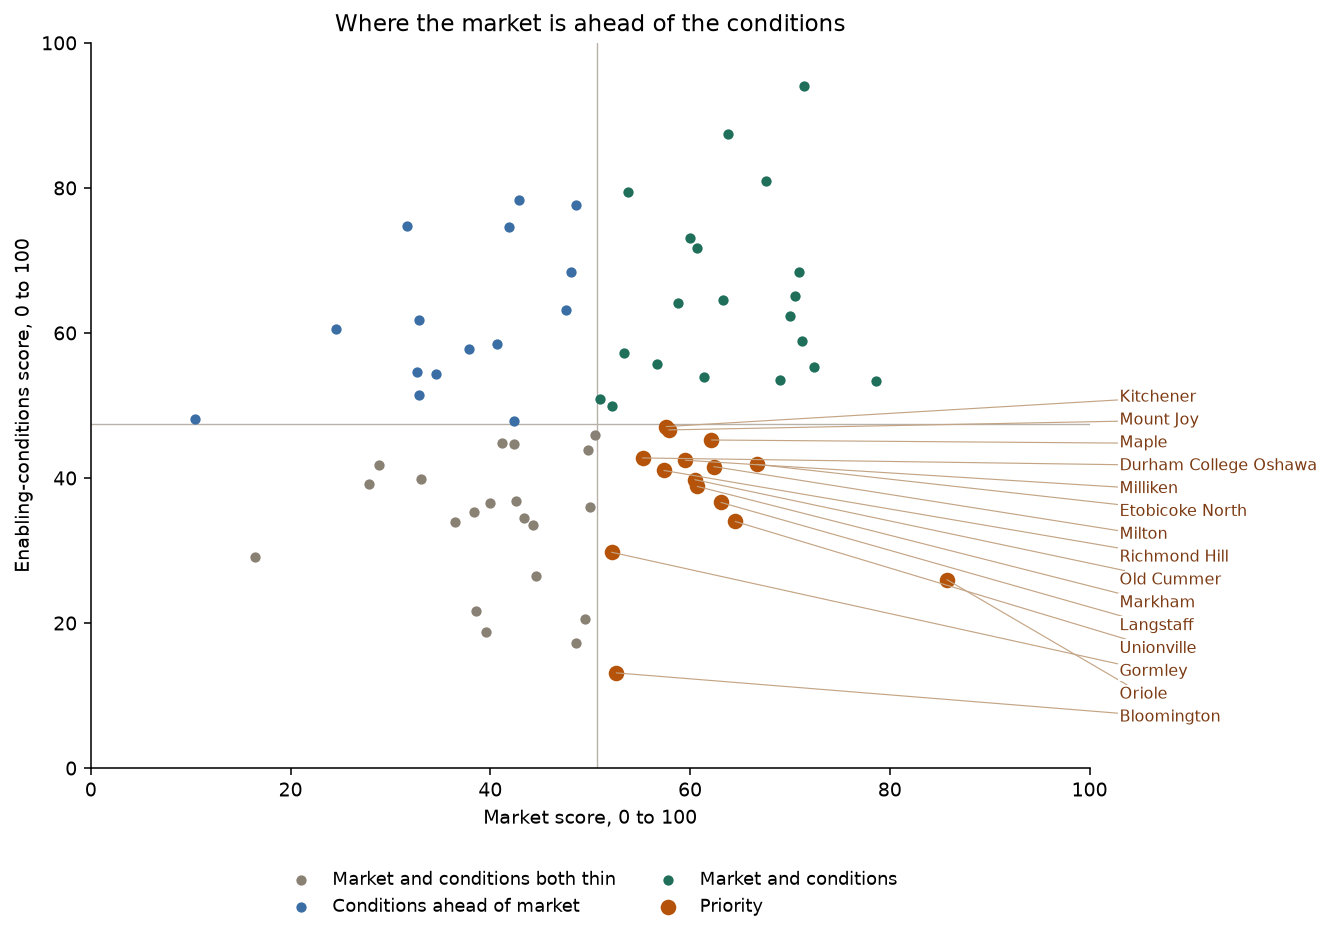

In [5]:
display(Image(filename=str(ROOT / "reports" / "figures" / "quadrant.png")))

## 5. Analysis 2, the primary likely constraint

I then compared each priority station with the stations that have both a strong market and strong conditions. The deficit on a condition is how many points the station sits below that reference median. The largest deficit is the primary likely constraint. If the second deficit is within 10 points, I report a tie, because the evidence does not support a single label.

I do not use a first-match rule. A fixed order would have called a station a parking problem whenever the 2019 lot was full, even when the bus gap was larger.

I repeated the deficit against the station's own line. Where the label changes, I flag it and I do not treat it as a firm recommendation.

I then wrote a competing-evidence row for each priority station and each Kitchener case station: the primary label, the second-largest deficit, the numbers behind the label, the condition that argues against it, and a confidence of high, medium, or low. Confidence is high only when one deficit is at least half the gap, the station's own line agrees, the land-use rule did not replace the deficit, and the station is not within 5 points of a median.

In [6]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)
from scorecard.pipeline import load
table, recs, meta = load()

cols = ["station_name","line_name","primary_likely","runner_up","constraint_share","is_tie",
        "confidence","near_cut","threshold_class",
        "deficit_service","deficit_feeder","deficit_walk","deficit_parking","deficit_fare",
        "primary_vs_corridor","label_changes_with_corridor"]
focus = table[table.quadrant.eq("priority")]
print(focus[cols].sort_values("constraint_share", ascending=False).to_string(index=False))
evidence = pd.read_csv(ROOT / "reports" / "evidence.csv")
print(evidence[["station_name","primary_label","second_label","confidence","supporting_evidence","contradictory_evidence"]].to_string(index=False))

         station_name      line_name primary_likely runner_up  constraint_share is_tie confidence near_cut     threshold_class  deficit_service  deficit_feeder  deficit_walk  deficit_parking  deficit_fare primary_vs_corridor  label_changes_with_corridor
            Kitchener      Kitchener           fare    feeder          0.687419  False     medium     True threshold-sensitive         1.339286       29.841270    -25.357143              NaN     68.571429                fare                        False
      Etobicoke North      Kitchener           walk    feeder          0.577809  False       high    False               clear        20.982143       21.031746     57.500000              NaN     -4.285714                walk                        False
Durham College Oshawa Lakeshore East           walk      fare          0.483283   True     medium     True               clear       -25.803571       10.714286     56.785714              NaN     50.000000                walk              

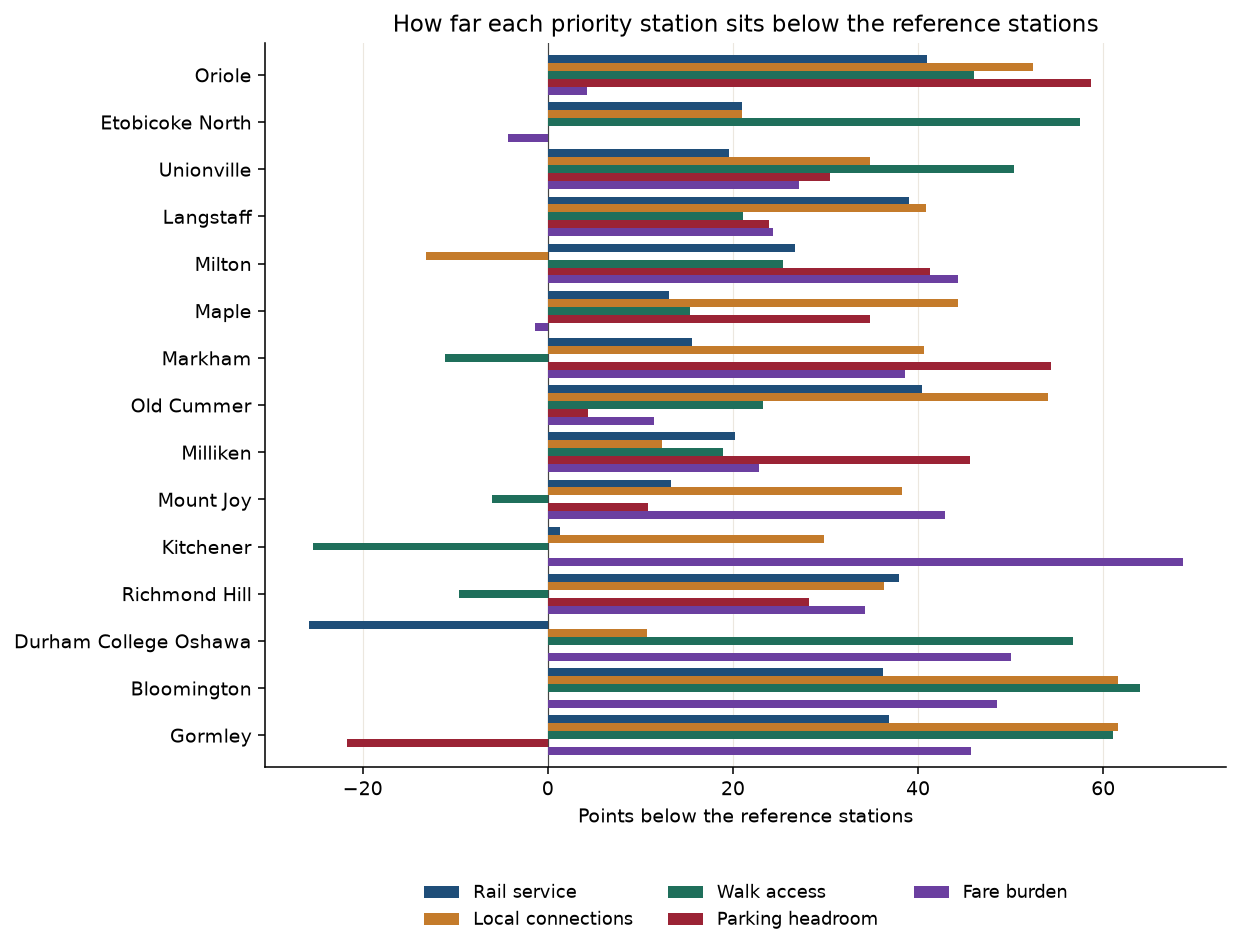

In [7]:
display(Image(filename=str(ROOT / "reports" / "figures" / "deficits.png")))

## 6. Kitchener line

I then looked at the Kitchener line on its own, because it is the corridor I can connect to work I already do in Guelph. The question here is whether the timetable is still a peak-commute product on the outer stations, while the census shows a hybrid-work market and the recovered GO market, in Metrolinx's 2024-25 annual report, is strong off-peak and on weekends.

Guelph Central's 2019 lot has 18 spaces, below the 50-space cutoff I use for the network parking score. I still report it here, because a lot that small and over capacity is part of the station's access story even if it should not dominate a network ranking.

In [8]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)
from scorecard.pipeline import load
table, recs, meta = load()

from scorecard.config import KITCHENER_CASE
kit = table[table.station_id.isin(KITCHENER_CASE)].sort_values("weekday_to_union")
cols = ["station_name","am_headway_min","midday_max_gap_min","span_hours","weekend_span_hours",
        "ivt_to_union_min","fare_to_union","generalized_cost","walk_pop","walk_jobs","shed_pop",
        "commute_to_toronto_share","shed_wfh_share","parking_spaces_2019","parking_utilization_2019",
        "feeder_am_arrivals","am_transfer_wait_min","quadrant","near_cut","primary_likely","confidence"]
print(kit[cols].to_string(index=False))

                station_name  am_headway_min  midday_max_gap_min  span_hours  weekend_span_hours  ivt_to_union_min  fare_to_union  generalized_cost    walk_pop   walk_jobs      shed_pop  commute_to_toronto_share  shed_wfh_share  parking_spaces_2019  parking_utilization_2019  feeder_am_arrivals  am_transfer_wait_min                        quadrant near_cut primary_likely confidence
                       Acton            30.0               330.0   17.966667           15.616667              64.5          14.25         53.623191 1683.986632   99.442243  21728.073873                  0.065995        0.277102                 46.0                  0.907115                 0.0                   NaN market and conditions both thin    False         feeder     medium
                   Kitchener            30.0               180.0   19.183333           16.800000              99.0          19.40         64.356211 4490.581845 2286.898673 374167.031739                  0.010357        0.314019     

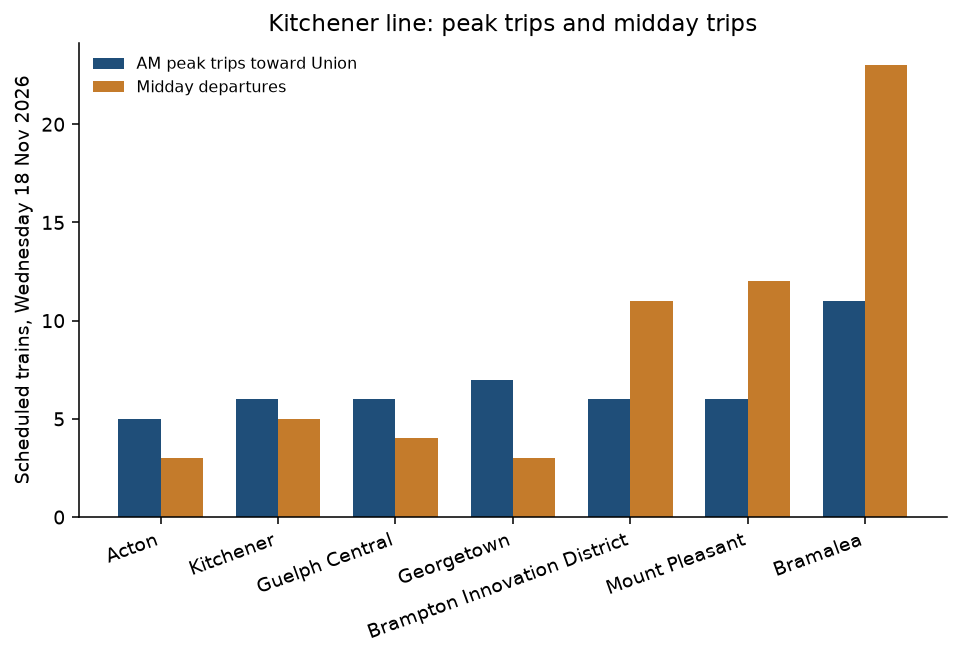

In [9]:
display(Image(filename=str(ROOT / "reports" / "figures" / "kitchener_service.png")))

## 7. Transfer audit for the stations I would act on

I did not audit every station. I limited this to the priority set and the Kitchener case stations, and to the direction that matters for a morning trip into Toronto: bus arrival, then train toward Union. Waits are capped at 60 minutes in the SQL, so a station with no midday train does not produce an unbounded gap. The cap is a reporting choice, and a median that sits on 60 minutes means many connections did not find a train inside the hour.

In [10]:
from scorecard.config import AM_PEAK, KITCHENER_CASE
waits = pd.read_parquet(ROOT / "data" / "processed" / "transfer_waits.parquet")
ids = set(table.loc[table.quadrant.eq("priority"), "station_id"]) | set(KITCHENER_CASE)
am = waits[(waits.direction.eq("bus_to_train")) & (waits.station_id.isin(ids)) & (waits.event_sec.between(*AM_PEAK))]
summary = am.groupby("station_id").wait_sec.agg(n="size", median_min=lambda s: s.median()/60, p90_min=lambda s: s.quantile(0.9)/60)
summary = summary.join(table.set_index("station_id")[["station_name","main_feeder_agency","primary_likely"]])
print(summary.sort_values("median_min", ascending=False).to_string())

              n  median_min    p90_min                  station_name main_feeder_agency primary_likely
station_id                                                                                            
RI           91   27.900000  60.000000                 Richmond Hill                yrt        service
OL           18   27.708333  60.000000                    Old Cummer                ttc         feeder
OR           16   26.891667  60.000000                        Oriole                ttc       land_use
LA           48   26.158333  60.000000                     Langstaff                yrt         feeder
MR           44   22.200000  32.328333                       Markham                ttc        parking
KI           85   22.000000  60.000000                     Kitchener            grt_bus           fare
GL          237   19.000000  29.180000                Guelph Central             guelph           fare
MK          227   18.666667  46.223333                      Milliken     

## 8. Recommendations

I wrote one action per priority station, named the owner, and named the measure I would track. Where the top two constraints are within 10 points, the action is a first test, not a single project. The full sentences are in `reports/executive_brief.md`.

In [11]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)
from scorecard.pipeline import load
table, recs, meta = load()

show = recs[recs.quadrant.eq("priority")][
    ["station_name","line_name","primary_likely","constraint_share","is_tie","second_constraint",
     "owner","relative_cost","timing","kpi"]
]
print(show.to_string(index=False))

         station_name      line_name    primary_likely  constraint_share  is_tie second_constraint                                           owner relative_cost                                      timing                                                                                           kpi
               Oriole  Richmond Hill          Land use              29.0   False               NaN                              Municipal planning          High                  Municipal planning horizon                                         People and jobs per hectare inside the 800 m walkshed
      Etobicoke North      Kitchener       Walk access              58.0   False               NaN Metrolinx station access, with the municipality        Medium                                1 to 3 years                      Population and jobs inside the 800 m walkshed after the connection opens
           Unionville    Stouffville          Land use              31.0   False               NaN     

## What I would not claim

I would not tell a senior manager that these stations have low ridership, or that adding a bus will produce a given number of riders. I would say which condition is furthest behind the stations that are otherwise in a similar position, how sure that label is, and who would have to act. If station-level PRESTO became available, the next step would be to test these labels against boardings, not to replace this table with a black-box model.

In [12]:
print((ROOT / "reports" / "executive_brief.md").read_text()[:2500])

# Where GO ridership cannot show up yet

## The question

I asked which GO and UP stations have a strong surrounding travel market, but weak walk access, local connections, rail service, parking headroom, or fare. I did not ask which stations have low ridership. Station boardings and PRESTO transactions are not open, so a ridership model would have been a guess. The scorecard is the evidence I can defend, and it is the question I would take to Transit Strategy and Insights.

## What I did, in order

I first took the current GO and UP Express schedules for Wednesday 2026-11-18, the Saturday, and the Sunday inside that feed. I measured the AM headway toward Union, the longest midday gap, the weekday span from the first train to the last, and the weekend span. Trip counts stay in the table as evidence. They do not enter the service score. I then placed every local bus stop within 250 m of a station, using the latest open feed from each of 14 municipal operators, and measured the scheduled